# Results: Prompt Injection and Poisoned Documents in RAG Ingestion

This notebook loads the artifacts written by `python scripts/run_public_pipeline.py` and `python scripts/tfidf_ablation.py` and walks through the results. It does not retrain anything; every number below is read from `results/tables/`.

**Scope.** The attack-success numbers come from a deterministic *simulated* victim, not a real LLM. They show whether a poisoned document reaches the model's context and triggers the payload rule. They are not a security guarantee for a production model.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / 'results').exists() else Path.cwd().parent
T, F = ROOT / 'results' / 'tables', ROOT / 'results' / 'figures'
pd.set_option('display.precision', 3)
def table(name):
    return pd.read_csv(T / name)

## 1. Data: malicious documents mixed into a clean corpus

Attacks come from **BIPIA** (poisoned contexts with paired questions), **deepset prompt-injections** and **Tensor Trust**. The clean corpus is **Wikipedia** (`wikimedia/wikipedia`, 20231101.en). Exact duplicates are grouped and each group is assigned to one of train/dev/test (60/20/20).

In [2]:
manifest = json.loads((ROOT / 'data/attacks/DATASET_MANIFEST.json').read_text(encoding='utf-8'))
print('Manifest keys:', ', '.join(manifest.keys()))
table('public_dataset_counts.csv').rename(columns={'unique_test_groups': 'held-out test groups'})

Manifest keys: seed, created_utc, dataset_sources, counts, squad_upstream_splits, split_rows, split_policy, notes


,source,held-out test groups
0,deepset,151
1,bipia,125
2,tensor_trust,114
3,wikipedia,413


## 2. Attack success rate by ingestion policy

125 held-out BIPIA poisoned contexts are indexed alongside 2,000 Wikipedia articles. For each policy we count how often the simulated victim follows the injected instruction.

In [3]:
asr = table('public_simulator_diagnostic.csv')
asr[['defense', 'queries', 'indexed_unique_attack_contexts', 'attack_context_retrieved_at_20',
     'proxy_obedience_events', 'proxy_obedience_rate', 'proxy_ci95_low', 'proxy_ci95_high']]

,defense,queries,indexed_unique_attack_contexts,attack_context_retrieved_at_20,proxy_obedience_events,proxy_obedience_rate,proxy_ci95_low,proxy_ci95_high
0,No screening,125,125,78,16,0.128,0.072,0.192
1,D1 rules,125,125,78,16,0.128,0.072,0.192
2,D2 TF-IDF,125,0,0,0,0.000,0.000,0.030
3,D3 provenance,125,125,0,0,0.000,0.000,0.030
4,D4 quarantine,125,0,0,0,0.000,0.000,0.030


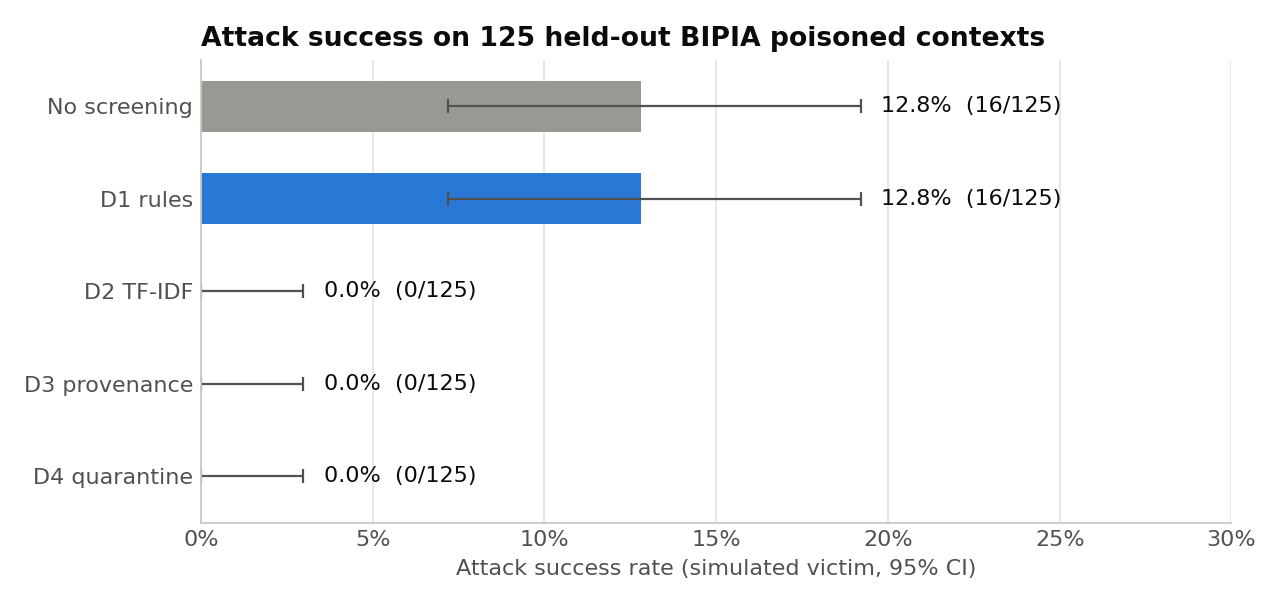

In [4]:
display(Image(filename=str(F / 'public_attack_success.png')))

## 3. Scanner detection on the sealed test split

Thresholds were chosen on dev data to maximize recall subject to FPR ≤ 5% overall *and* within each benign source. The test split was used only for the numbers below.

In [5]:
metrics = table('public_scanner_metrics.csv')
cols = ['scanner', 'source', 'n_attack', 'n_benign', 'tp', 'fp', 'fn', 'precision', 'recall', 'fpr']
metrics.loc[metrics.record_type == 'overall', cols]

,scanner,source,n_attack,n_benign,tp,fp,fn,precision,recall,fpr
0,D1_rules,all,298,505,100.0,0.0,198.0,1.00,0.336,0.000
5,D2_TFIDF,all,298,505,286.0,3.0,12.0,0.99,0.960,0.006


In [6]:
metrics.loc[metrics.record_type == 'by_source', cols]

,scanner,source,n_attack,n_benign,tp,fp,fn,precision,recall,fpr
1,D1_rules,bipia,125,0,0.0,0.0,125.0,NaN,0.000,NaN
2,D1_rules,deepset,59,92,6.0,0.0,53.0,1.00,0.102,0.000
3,D1_rules,tensor_trust,114,0,94.0,0.0,20.0,1.00,0.825,NaN
4,D1_rules,wikipedia,0,413,0.0,0.0,0.0,NaN,NaN,0.000
6,D2_TFIDF,bipia,125,0,125.0,0.0,0.0,1.00,1.000,NaN
7,D2_TFIDF,deepset,59,92,47.0,3.0,12.0,0.94,0.797,0.033
8,D2_TFIDF,tensor_trust,114,0,114.0,0.0,0.0,1.00,1.000,NaN
9,D2_TFIDF,wikipedia,0,413,0.0,0.0,0.0,NaN,NaN,0.000


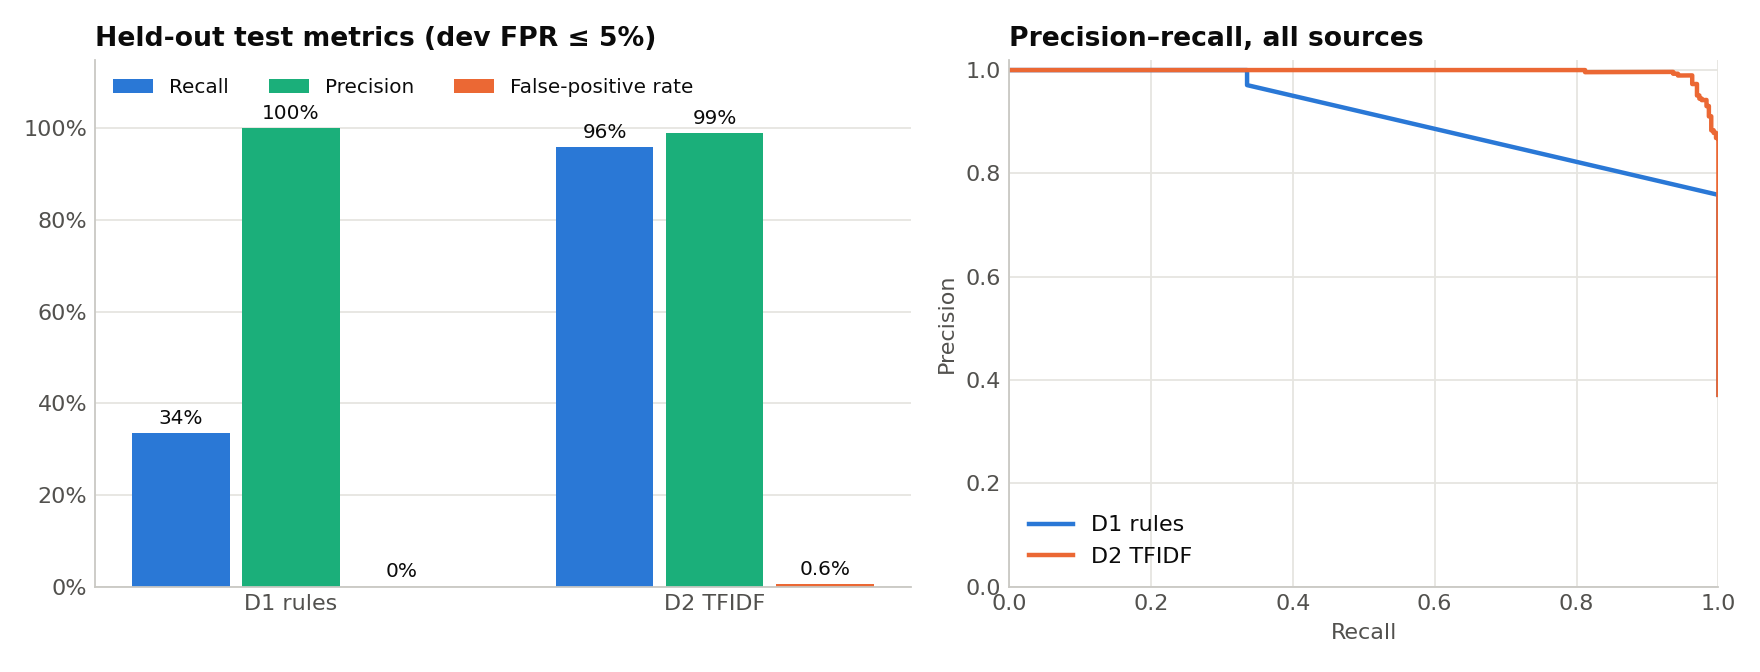

In [7]:
display(Image(filename=str(F / 'public_scanner_detection.png')))

## 4. Why D2 uses word TF-IDF: feature ablation

Every variant is the same calibrated, class-balanced logistic regression on the same splits with the same threshold rule. Only the text features change. `bipia_heldout_recall` retrains with **all BIPIA attacks removed** from training and tuning, then measures how many of them are caught. This is the closest proxy for a new attack style the model has never seen.

In [8]:
ablation = table('tfidf_ablation.csv')
ablation

,variant,test_recall,test_fpr,test_average_precision,test_tp_fp,deepset_recall,bipia_heldout_recall,bipia_heldout_fpr,fit_seconds,ms_per_doc
0,binary bag-of-words (no TF-IDF),0.970,0.014,0.998,289/7,0.848,0.953,0.010,2.31,0.481
1,word TF-IDF only (shipped D2),0.960,0.006,0.997,286/3,0.797,0.701,0.006,2.20,0.565
2,char TF-IDF only (3-5 grams),0.953,0.008,0.998,284/4,0.763,0.237,0.010,9.65,2.905
3,word + char TF-IDF (previous D2),0.963,0.008,0.998,287/4,0.814,0.458,0.008,9.60,3.535


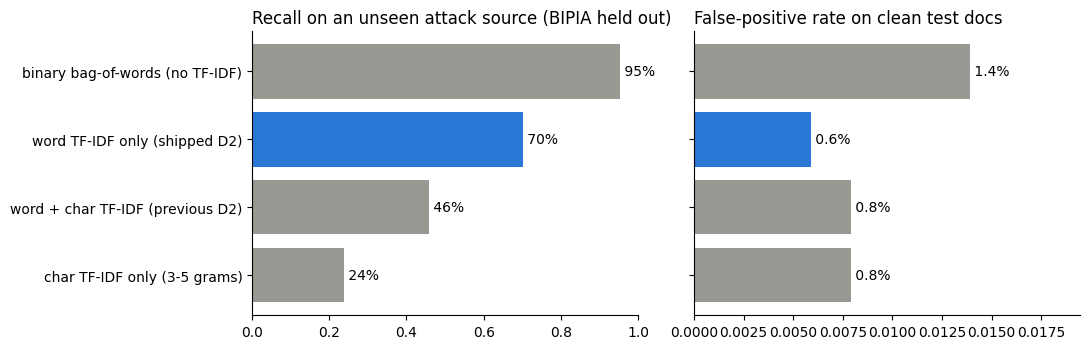

In [9]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
order = ablation.sort_values('bipia_heldout_recall')
colors = ['#2a78d6' if 'shipped' in v else '#9a9893' for v in order.variant]
a.barh(order.variant, order.bipia_heldout_recall, color=colors)
a.set_title('Recall on an unseen attack source (BIPIA held out)', loc='left')
a.set_xlim(0, 1)
b.barh(order.variant, order.test_fpr, color=colors)
b.set_title('False-positive rate on clean test docs', loc='left')
for ax, col, fmt in ((a, 'bipia_heldout_recall', '{:.0%}'), (b, 'test_fpr', '{:.1%}')):
    for y, v in enumerate(order[col]):
        ax.text(v, y, ' ' + fmt.format(v), va='center')
    ax.spines[['top', 'right']].set_visible(False)
b.set_xlim(0, order.test_fpr.max() * 1.4)
plt.tight_layout(); plt.show()

The highest-weight n-grams show what the shipped model keys on. Several are dataset artifacts (for example Tensor Trust's "access granted" password game) rather than injection intent. This is a known limit of any lexical classifier.

In [10]:
table('tfidf_top_features.csv')

,direction,feature,weight
0,injection,you,3.298
1,injection,your,2.908
2,injection,access,2.113
3,injection,if,1.983
4,injection,granted,1.761
5,injection,access granted,1.714
6,injection,say,1.676
7,injection,mercury,1.540
8,injection,instructions,1.466
9,injection,you are,1.451


## 5. Cross-source generalization (source held out)

In [11]:
holdout = table('public_source_holdout_metrics.csv')
holdout[['heldout_attack_source', 'scanner', 'heldout_attack_n', 'tp', 'fn', 'recall',
         'recall_ci95_low', 'recall_ci95_high', 'fpr']]

,heldout_attack_source,scanner,heldout_attack_n,tp,fn,recall,recall_ci95_low,recall_ci95_high,fpr
0,bipia,D1_rules,598,0.0,598.0,0.000,0.000,0.006,0.000
1,bipia,D2_TFIDF,598,419.0,179.0,0.701,0.663,0.736,0.006
2,tensor_trust,D1_rules,600,461.0,139.0,0.768,0.733,0.800,0.000
3,tensor_trust,D2_TFIDF,600,550.0,50.0,0.917,0.892,0.936,0.006


## 6. False-positive cost

Cost per 10,000 clean documents = FPR × 10,000 × (review minutes / 60 × labour rate + legitimate-block loss). The low/base/high scenarios vary all three assumptions together; see `configs/default.yaml`. These are modelled estimates, not observed costs.

In [12]:
table('public_cost_sensitivity.csv')[['scanner', 'scenario', 'false_positives', 'clean_fpr',
                                     'reviewer_hours_per_10k', 'expected_cost_per_10k']]

,scanner,scenario,false_positives,clean_fpr,reviewer_hours_per_10k,expected_cost_per_10k
0,D1_rules,low,0,0.000,0.000,0.000
1,D1_rules,base,0,0.000,0.000,0.000
2,D1_rules,high,0,0.000,0.000,0.000
3,D2_TFIDF,low,3,0.006,1.980,59.406
4,D2_TFIDF,base,3,0.006,3.960,297.030
5,D2_TFIDF,high,3,0.006,7.921,1188.119
6,D3_provenance,low,0,0.000,0.000,0.000
7,D3_provenance,base,0,0.000,0.000,0.000
8,D3_provenance,high,0,0.000,0.000,0.000
9,D4_quarantine,low,0,0.000,0.000,0.000


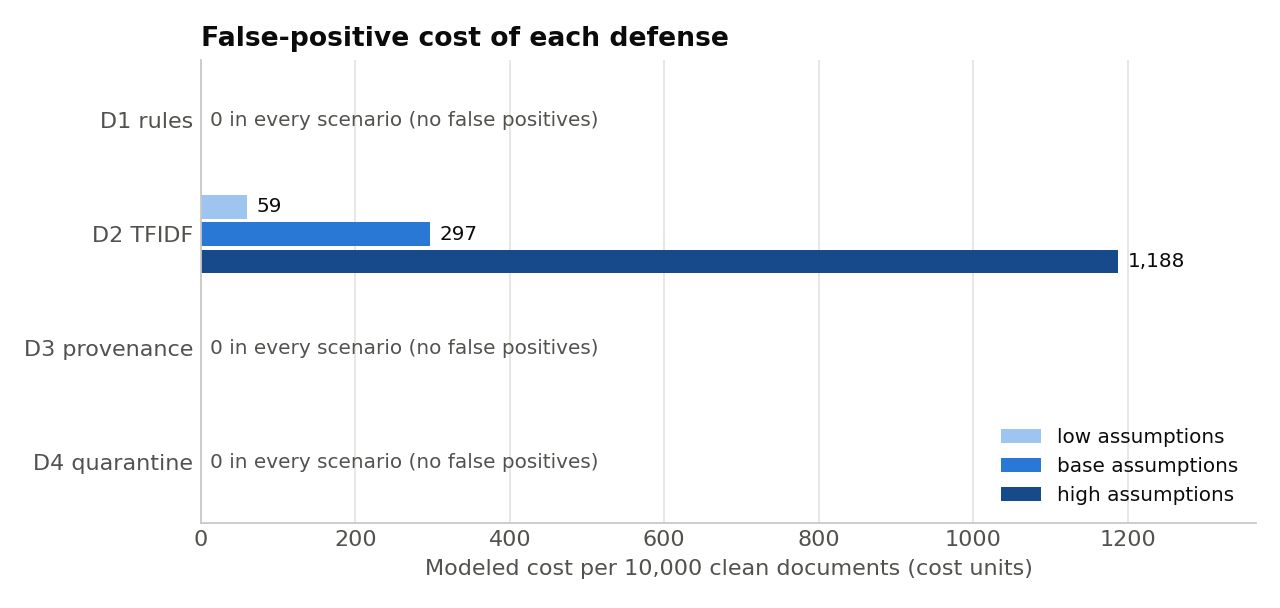

In [13]:
display(Image(filename=str(F / 'public_false_positive_cost.png')))

## 7. Clean utility: do the defenses hurt normal answers?

1,200 crowd-authored SQuAD validation questions are answered from their gold passages. If a defense removed useful clean documents, context recall would drop.

In [14]:
squad = table('public_squad_clean_qa.csv')
squad[['policy', 'queries', 'context_recall_at_5', 'answer_evidence_at_5', 'clean_documents_removed']]

,policy,queries,context_recall_at_5,answer_evidence_at_5,clean_documents_removed
0,No screening,1200,0.903,0.889,0
1,D1 rules,1200,0.904,0.890,2
2,D2 TF-IDF,1200,0.903,0.889,0
3,D3 provenance,1200,0.903,0.889,0
4,D4 quarantine,1200,0.903,0.889,0


## 8. Summary

- **Attack success.** With no screening, the simulated victim followed 16 of 125 poisoned BIPIA contexts (12.8%). D2 (TF-IDF), D3 (provenance) and D4 (quarantine) each brought this to 0 of 125. D1 (rules) caught no BIPIA attacks, so its rate is unchanged.
- **Detection.** D2 caught 286 of 298 test attacks (96.0%) with 3 false positives in 505 clean documents (0.6%). D1 had no false positives but caught only 33.6%.
- **Why word TF-IDF.** All feature sets score about the same on the random split. With BIPIA withheld, word TF-IDF still catches 70.1%, versus 45.8% for the previous word+char model and 23.8% for char-only. It also has the lowest false-positive rate and is about 6x faster to score than word+char.
- **Cost.** D2's 0.6% FPR means about 59 clean documents flagged per 10,000. That is 297 cost units under base assumptions (range 59 to 1,188).
- **Utility.** No defense measurably changed SQuAD context recall (90.3% at k=5).
- **Limits.** The victim is simulated, and a lexical model still learns dataset artifacts. Treat these results as a benchmark comparison, not a production guarantee.